# Amazon-Tocantins Release Region - GLORYS12 bathymetry

Same release geometry as `release_polygon_map.ipynb`, but every bathymetry / land-mask
figure now uses the **real GLORYS12 model bathymetry** read from the NEMO mesh files
instead of the coarse Natural Earth depth polygons.

- `Hgr_cmesh.nc` - horizontal mesh (`glamt`, `gphit` = T-point lon/lat)
- `Zgr_cmesh2.nc` - vertical mesh (`mbathy` = number of wet levels, `deptht` = partial-step
  bottom depth at T points)

A cell is **land** where `mbathy == 0`; elsewhere `deptht` is the model's true bottom depth,
partial bottom cell included. That mask is what actually governs where particles can sit.

The Coles-style lat/lon box turned out to be **36% land** - it swallows eastern Marajo
and part of the Para mainland. The replacement is a **band along the mouth axis**:

- **left edge**  - the old release line, prolonged SE until it strikes the Para bank,
  so the southern tip rests on the coast just as the northern tip rests on the Amazon coast
- **right edge** - that edge pushed 0.8 deg seaward, perpendicular to the axis

In [1]:
import warnings
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.geometry import Polygon, box as sbox
from shapely.ops import unary_union
from matplotlib.path import Path as MplPath

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
warnings.filterwarnings('ignore', category=RuntimeWarning)

# --- GLORYS12 / NEMO mesh ---
pathUVW = '/work/bk1450/b383184/Amazon/Mercator/data/variables/'
Hgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc'
Zgr     = '/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc'

# map window, reused everywhere
EXTENT = [-52, -46, -3, 4]

## 1. Release geometry

In [2]:
# --- OLD: release line ---
old_lons = [-49.916, -49.083]
old_lats = [1.166, -0.083]

# --- Coles-style box (kept for comparison) ---
LON_W, LON_E = -50.0, -48.2
LAT_S, LAT_N = -0.75, 0.85
polygon_lons = [LON_W, LON_E, LON_E, LON_W, LON_W]
polygon_lats = [LAT_S, LAT_S, LAT_N, LAT_N, LAT_S]

# --- NEW: green release band ---
#   A  Amazon coast  - start of the old release line
#   B  Para coast    - old line prolonged SE until it strikes the Para bank
#   B' seaward corner off B  (pushed NE, not perpendicular: the Maranhao coast
#                             bends east, so a perpendicular corner runs aground)
#   A' seaward corner off A  (0.8 deg perpendicular)
green_lons = [-49.916, -48.392, -47.8, -49.250, -49.916]
green_lats = [  1.166,  -1.05,  -0.6,   1.610,    1.166]

## 2. Map

`cfeature.RIVERS` and the Natural Earth coastline are downloaded on first use
(cached under `~/.local/share/cartopy`).

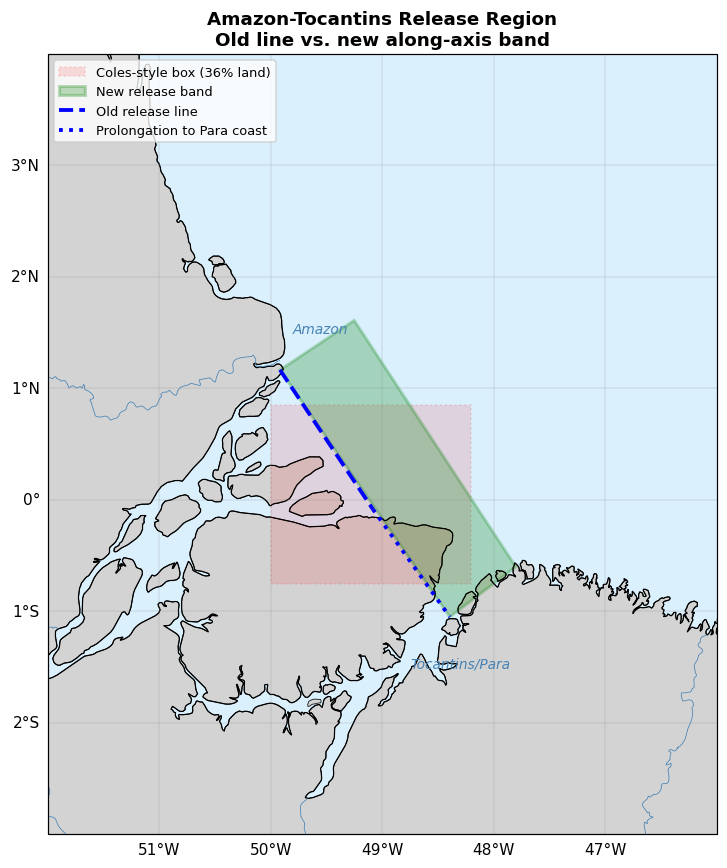

Saved: release_polygon_map_glorys.png


In [3]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent([-52, -46, -3, 4], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.OCEAN, facecolor='lightskyblue', alpha=0.3)
ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.RIVERS, linewidth=0.5, edgecolor='steelblue')

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

# Coles-style box (rejected: too much land)
ax.fill(polygon_lons, polygon_lats, transform=ccrs.PlateCarree(),
        facecolor='red', alpha=0.12, edgecolor='red', linewidth=1.2,
        linestyle=':', label='Coles-style box (36% land)')

# New green band
ax.fill(green_lons, green_lats, transform=ccrs.PlateCarree(),
        facecolor='green', alpha=0.25, edgecolor='green', linewidth=2,
        label='New release band')

# Old release line
ax.plot(old_lons, old_lats, transform=ccrs.PlateCarree(),
        color='blue', linewidth=2.5, linestyle='--', label='Old release line')

# The prolongation, drawn dotted so the extension is visible
ax.plot([old_lons[1], green_lons[1]], [old_lats[1], green_lats[1]], transform=ccrs.PlateCarree(),
        color='blue', linewidth=2.5, linestyle=':', label='Prolongation to Para coast')

ax.text(-49.8, 1.5, 'Amazon', fontsize=9, fontstyle='italic',
        transform=ccrs.PlateCarree(), color='steelblue')
ax.text(-48.75, -1.5, 'Tocantins/Para', fontsize=9, fontstyle='italic',
        transform=ccrs.PlateCarree(), color='steelblue')

ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Amazon-Tocantins Release Region\nOld line vs. new along-axis band',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('release_polygon_map_glorys.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved: release_polygon_map_glorys.png")

## 3. GLORYS12 bathymetry from the NEMO mesh

`deptht` is the depth of the deepest T-point (partial bottom cell included), i.e. the model
bottom depth. `mbathy` counts wet levels, so `mbathy == 0` marks land - on those cells
`deptht` is meaningless filler and is masked out.

The mesh is global-ish (499 x 1260); we clip to the map window first so nothing large is
carried around.

In [4]:
hgr = xr.open_dataset(Hgr)
zgr = xr.open_dataset(Zgr)

lon2d = hgr['glamt'].isel(t=0).values          # T-point longitudes (y, x)
lat2d = hgr['gphit'].isel(t=0).values          # T-point latitudes  (y, x)
mbathy = zgr['mbathy'].isel(t=0).values        # wet-level count, 0 = land
deptht = zgr['deptht'].isel(t=0).values        # bottom depth at T points [m]

# --- clip to the map window -------------------------------------------------
pad = 0.5
inbox = ((lon2d >= EXTENT[0] - pad) & (lon2d <= EXTENT[1] + pad) &
         (lat2d >= EXTENT[2] - pad) & (lat2d <= EXTENT[3] + pad))
yi, xi = np.where(inbox)
ys, ye = yi.min(), yi.max() + 1
xs, xe = xi.min(), xi.max() + 1
sl = (slice(ys, ye), slice(xs, xe))

lon_s, lat_s = lon2d[sl], lat2d[sl]
mb_s, dp_s   = mbathy[sl], deptht[sl]

# --- model bathymetry: masked on land ---------------------------------------
land_mask = (mb_s == 0)
bathy = np.where(land_mask, np.nan, dp_s)

print(f"subset shape        : {bathy.shape}")
print(f"lon range           : {lon_s.min():.3f} .. {lon_s.max():.3f}")
print(f"lat range           : {lat_s.min():.3f} .. {lat_s.max():.3f}")
print(f"grid spacing (deg)  : {np.diff(lon_s[0]).mean():.4f} lon, "
      f"{np.diff(lat_s[:, 0]).mean():.4f} lat")
print(f"land cells          : {land_mask.sum()} / {land_mask.size} "
      f"({100 * land_mask.mean():.1f}%)")
print(f"depth range (wet)   : {np.nanmin(bathy):.1f} .. {np.nanmax(bathy):.1f} m")

subset shape        : (97, 85)
lon range           : -52.500 .. -45.500
lat range           : -3.498 .. 4.495
grid spacing (deg)  : 0.0833 lon, 0.0833 lat
land cells          : 4348 / 8245 (52.7%)
depth range (wet)   : 6.4 .. 3829.8 m


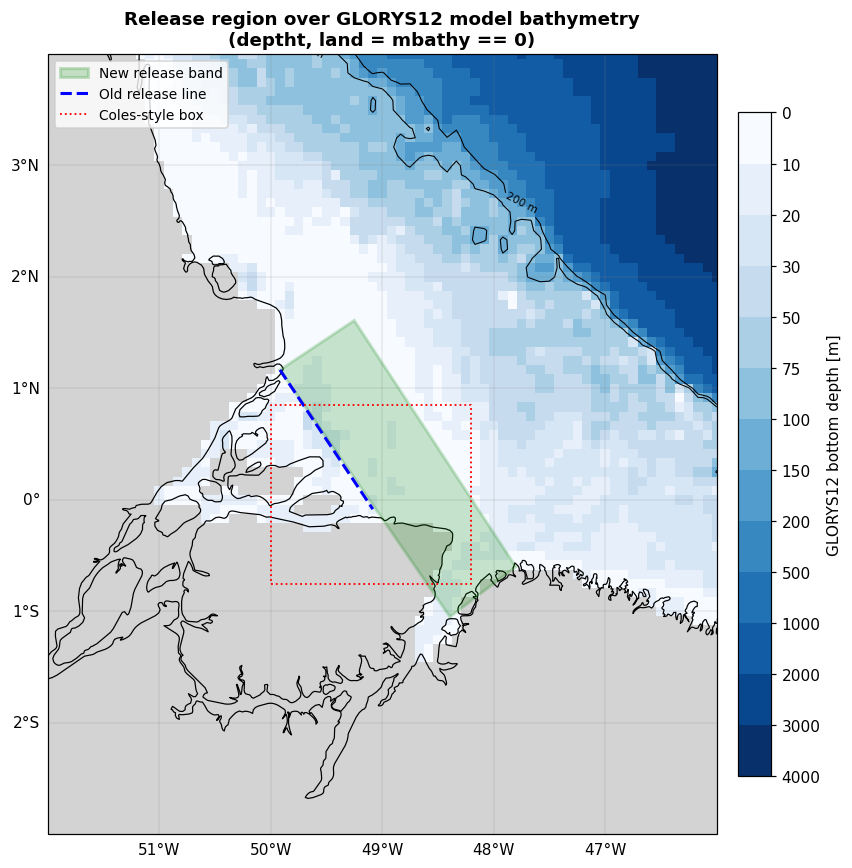

In [5]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())

# log-ish depth scale: the shelf detail near the mouth is what matters here
levels = [0, 10, 20, 30, 50, 75, 100, 150, 200, 500, 1000, 2000, 3000, 4000]
norm = mcolors.BoundaryNorm(levels, ncolors=256)

pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(),
                   cmap='Blues', norm=norm, shading='auto', zorder=0)

# model land mask (mbathy == 0), drawn from the model grid itself
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan),
              transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(['lightgray']),
              shading='auto', zorder=1)

# 100 m and 200 m shelf-break isobaths
cs = ax.contour(lon_s, lat_s, bathy, levels=[100, 200], colors='k',
                linewidths=0.7, transform=ccrs.PlateCarree(), zorder=2)
ax.clabel(cs, fmt='%d m', fontsize=7)

ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

ax.fill(green_lons, green_lats, transform=ccrs.PlateCarree(),
        facecolor='green', alpha=0.20, edgecolor='green', linewidth=2, zorder=4,
        label='New release band')
ax.plot(old_lons, old_lats, transform=ccrs.PlateCarree(),
        color='blue', linewidth=2, linestyle='--', zorder=4, label='Old release line')
ax.plot(polygon_lons, polygon_lats, transform=ccrs.PlateCarree(),
        color='red', linewidth=1.2, linestyle=':', zorder=4, label='Coles-style box')

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85,
                  ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]')
cb.ax.invert_yaxis()

ax.legend(loc='upper left', fontsize=9)
ax.set_title('Release region over GLORYS12 model bathymetry\n'
             '(deptht, land = mbathy == 0)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('release_polygon_bathymetry_glorys.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Land contamination: box vs. band (Natural Earth coastline)

Kept for continuity with the original notebook - these numbers come from the Natural Earth
10 m land polygons, a coastline approximation. Section 5 repeats the test against the real
GLORYS12 mask, which is the one that governs where particles can sit.

In [6]:
land = unary_union([g.geometry for g in shpreader.Reader(
    shpreader.natural_earth('10m', 'physical', 'land')).records()])

regions = {'Coles-style box': sbox(LON_W, LAT_S, LON_E, LAT_N),
           'New green band' : Polygon(zip(green_lons[:-1], green_lats[:-1]))}

print(f"{'region':18s} {'area':>8s} {'land %':>8s} {'water area':>11s}")
print("-" * 48)
for nm, poly in regions.items():
    land_area = poly.intersection(land).area
    print(f"{nm:18s} {poly.area:8.3f} {100*land_area/poly.area:7.1f}% "
          f"{poly.area - land_area:10.3f}")
print("\n(areas in square degrees)")

region                 area   land %  water area
------------------------------------------------
Coles-style box       2.880    36.1%      1.841
New green band        2.057    10.4%      1.843

(areas in square degrees)


## 5. GLORYS12 land-mask check

Now against the actual model mask. Every T point of the clipped mesh is tested for
containment in each polygon, then split wet / dry by `mbathy`. Because the band is a
quadrilateral rather than a lat/lon box, containment is done with the polygon itself,
not with a bounding-box slice.

In [7]:
def cells_in(poly_lons, poly_lats):
    """Boolean mask of T points whose centre falls inside the polygon."""
    path = MplPath(np.column_stack([poly_lons, poly_lats]))
    pts = np.column_stack([lon_s.ravel(), lat_s.ravel()])
    return path.contains_points(pts).reshape(lon_s.shape)

regions_g = {
    'Coles-style box': (polygon_lons, polygon_lats),
    'New green band' : (green_lons,   green_lats),
}

print(f"{'region':18s} {'cells':>7s} {'wet':>7s} {'land':>7s} {'land %':>8s} "
      f"{'mean depth':>11s} {'max depth':>10s}")
print('-' * 74)

masks = {}
for nm, (plons, plats) in regions_g.items():
    inside = cells_in(plons, plats)
    masks[nm] = inside
    n_tot  = int(inside.sum())
    n_land = int((inside & land_mask).sum())
    n_wet  = n_tot - n_land
    d = bathy[inside & ~land_mask]
    print(f"{nm:18s} {n_tot:7d} {n_wet:7d} {n_land:7d} "
          f"{100 * n_land / n_tot:7.1f}% {np.nanmean(d):10.1f} m {np.nanmax(d):8.1f} m")

print('\n(GLORYS12 T cells, land defined as mbathy == 0)')

region               cells     wet    land   land %  mean depth  max depth
--------------------------------------------------------------------------
Coles-style box        440     293     147    33.4%        9.4 m     34.3 m
New green band         296     267      29     9.8%        8.4 m     25.1 m

(GLORYS12 T cells, land defined as mbathy == 0)


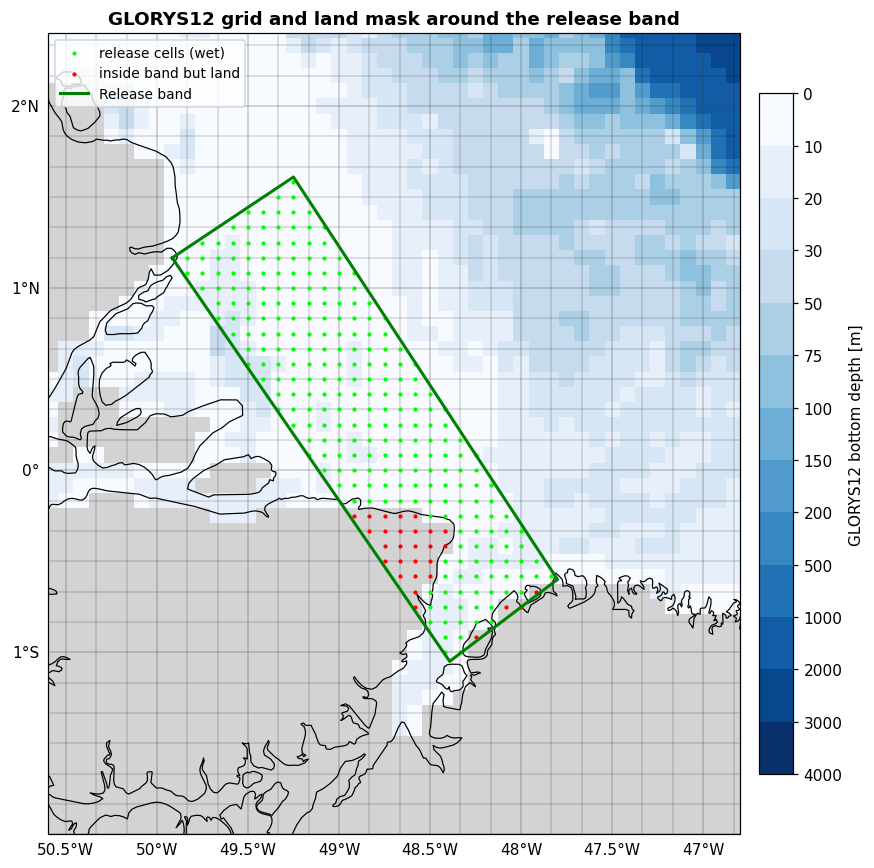

In [8]:
band_inside = masks['New green band']
wet_band = band_inside & ~land_mask

fig, ax = plt.subplots(figsize=(9, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent([-50.6, -46.8, -2.0, 2.4], crs=ccrs.PlateCarree())

pc = ax.pcolormesh(lon_s, lat_s, bathy, transform=ccrs.PlateCarree(),
                   cmap='Blues', norm=norm, shading='auto', zorder=0)
ax.pcolormesh(lon_s, lat_s, np.where(land_mask, 1.0, np.nan),
              transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(['lightgray']),
              shading='auto', zorder=1)

# model grid lines, from the mesh itself (every 2nd line to stay readable)
for j in range(0, lon_s.shape[0], 2):
    ax.plot(lon_s[j], lat_s[j], transform=ccrs.PlateCarree(), color='k', lw=0.15, zorder=2)
for i in range(0, lon_s.shape[1], 2):
    ax.plot(lon_s[:, i], lat_s[:, i], transform=ccrs.PlateCarree(), color='k', lw=0.15, zorder=2)

# release cells, wet vs dry
ax.scatter(lon_s[wet_band], lat_s[wet_band], s=3, color='lime',
           transform=ccrs.PlateCarree(), zorder=4, label='release cells (wet)')
dry_band = band_inside & land_mask
ax.scatter(lon_s[dry_band], lat_s[dry_band], s=3, color='red',
           transform=ccrs.PlateCarree(), zorder=4, label='inside band but land')

ax.plot(green_lons, green_lats, transform=ccrs.PlateCarree(),
        color='green', lw=2, zorder=5, label='Release band')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

cb = plt.colorbar(pc, ax=ax, orientation='vertical', pad=0.02, shrink=0.85, ticks=levels)
cb.set_label('GLORYS12 bottom depth [m]')
cb.ax.invert_yaxis()

ax.legend(loc='upper left', fontsize=9)
ax.set_title('GLORYS12 grid and land mask around the release band',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('release_polygon_glorys_mask_real.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Depth distribution of the release cells

How deep the water is where particles would actually be seeded.

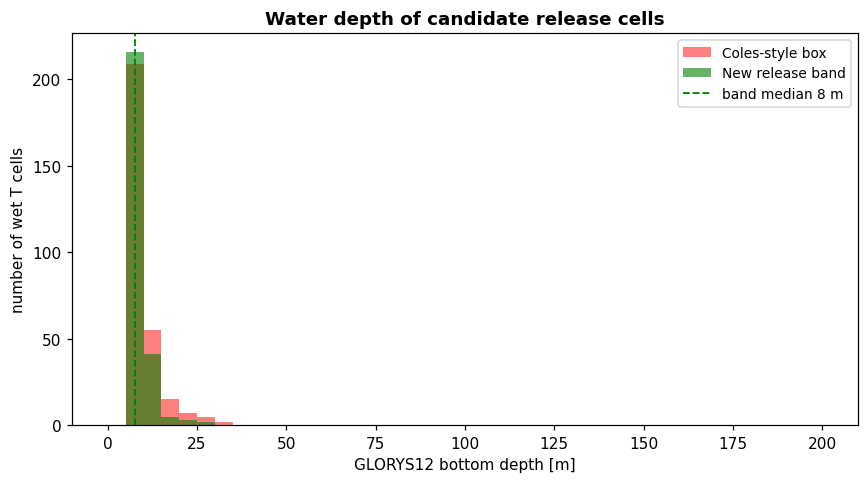

Coles-style box    n=  293  min=    6.4  median=    7.9  mean=    9.4  max=    34.3 m   shelf (<200 m): 100.0%
New green band     n=  267  min=    6.4  median=    7.6  mean=    8.4  max=    25.1 m   shelf (<200 m): 100.0%


In [9]:
d_band = bathy[wet_band]
d_box  = bathy[masks['Coles-style box'] & ~land_mask]

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, 205, 5)
ax.hist(d_box,  bins=bins, alpha=0.5, color='red',   label='Coles-style box')
ax.hist(d_band, bins=bins, alpha=0.6, color='green', label='New release band')
ax.axvline(np.median(d_band), color='green', ls='--', lw=1.2,
           label=f'band median {np.median(d_band):.0f} m')
ax.set_xlabel('GLORYS12 bottom depth [m]')
ax.set_ylabel('number of wet T cells')
ax.set_title('Water depth of candidate release cells', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('release_polygon_depth_hist.png', dpi=200, bbox_inches='tight')
plt.show()

for nm, d in [('Coles-style box', d_box), ('New green band', d_band)]:
    print(f"{nm:18s} n={d.size:5d}  min={d.min():7.1f}  median={np.median(d):7.1f}  "
          f"mean={d.mean():7.1f}  max={d.max():8.1f} m   "
          f"shelf (<200 m): {100 * (d < 200).mean():.1f}%")

## Notes

- Bathymetry and land mask come from the GLORYS12 NEMO mesh (`Zgr_cmesh2.nc`), not from
  Natural Earth: `deptht` is the partial-step bottom depth at T points and `mbathy == 0`
  is land. This is the mask the particle code sees.
- The band is a quadrilateral, not a lat/lon box, so seeding must sample inside the polygon
  (`shapely.contains` / `matplotlib.path.contains_points`) rather than from a regular
  lon/lat mesh - and then drop the cells where `mbathy == 0`.
- Corner B' is pushed NE rather than straight perpendicular. The Maranhao coast turns east
  past the Para mouth, so the perpendicular corner (47.73 W, 0.68 S) sits on land.
- The southern tip B rests on the Para bank at 1.12 S, mirroring the northern tip A on the
  Amazon coast, so the Tocantins/Para mouth is fully covered.
- Model land fraction (section 5) differs from the Natural Earth figure (section 4): the
  1/12 deg model coastline is blockier than the 10 m coastline polygons, so the two never
  agree exactly. The model number is the one to quote.